# Gym demo

Demonstrate the use of the the Gym interface and screen capture support

In [ ]:
%pip uninstall opencv-contrib-python

In [8]:
%matplotlib inline

import matplotlib.pyplot as plt
import sys
import os
import numpy as np
import pandas as pd
import glob as glob
import time
import pickle
from omegaconf import OmegaConf
import cv2

# add custom paths
sys.path.extend([os.path.abspath('./assetto_corsa_gym')])
import AssettoCorsaEnv.assettoCorsa as assettoCorsa

# Configure the logging system
import logging
logger = logging.getLogger(__name__)
logging.basicConfig(
    level=logging.INFO,  # Set the logging level (DEBUG, INFO, WARNING, ERROR, CRITICAL)
    format='%(asctime)s - %(name)s - %(levelname)s - %(message)s',  # Format of the log messages
    datefmt='%Y-%m-%d %H:%M:%S',  # Format of the timestamp
)



## Load config file

In [9]:
config = OmegaConf.load("config.yml")

config.AssettoCorsa.screen_capture_enable = False

# Create env object

In [10]:
env = assettoCorsa.make_ac_env(cfg=config, work_dir="output")


INFO:AssettoCorsaEnv.ac_env:Setting track ks_barcelona-layout_gp
INFO:AssettoCorsaEnv.track:Track loaded from: C:\Users\rhysi\Documents\Projects\Masters Project\assetto_corsa_gym\assetto_corsa_gym\AssettoCorsaEnv\../AssettoCorsaConfigs\tracks\ks_barcelona-layout_gp.csv Found 3000 segments downsampled by 10= 300 segments
INFO:AssettoCorsaEnv.reference_lap:Reference Lap. Loading: C:\Users\rhysi\Documents\Projects\Masters Project\assetto_corsa_gym\assetto_corsa_gym\AssettoCorsaEnv\../AssettoCorsaConfigs\tracks\ks_barcelona-layout_gp-racing_line_fixed.csv
INFO:AssettoCorsaEnv.reference_lap:Using curvature from racing line file
INFO:AssettoCorsaEnv.sensors_ray_casting:spatial_hash len 109
C:\Users\rhysi\Downloads\Anaconda\envs\p309\lib\site-packages\gym\spaces\box.py:73: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(
INFO:AssettoCorsaEnv.ac_env:Adding previous obs to state 25*3 = 100
INFO:AssettoCorsaEnv.ac_env:state_dim 125
INFO:AssettoCorsaEnv.ac_env:a

# Show static info

In [11]:
static_info = env.client.simulation_management.get_static_info()
ac_mod_config = env.client.simulation_management.get_config()

logger.info("Static info:")
for i in static_info:
    logger.info(f"{i}: {static_info[i]}")
logger.info("AC Mod config:")
for i in ac_mod_config:
    logger.info(f"{i}: {ac_mod_config[i]}")


INFO:__main__:Static info:
INFO:__main__:CAR_WHEELBASE: 2.799566172291971
INFO:__main__:TrackConfiguration: layout_gp
INFO:__main__:TyreContactPoint_RL: [256.708984375, -6.580214500427246, -324.8556213378906]
INFO:__main__:WindDirection: 359
INFO:__main__:isCarInPit: 0
INFO:__main__:CAR_TRACK: 1.5422593947006498
INFO:__main__:isCarInPitlane: 0
INFO:__main__:TrackName: ks_barcelona
INFO:__main__:autoShifterOn: 0
INFO:__main__:TyreContactPoint_RR: [257.3779296875, -6.556824207305908, -323.4661865234375]
INFO:__main__:CAR_WHEEL_R: [0.26899999380111694, 0.26899999380111694, 0.2784999907016754, 0.2784999907016754]
INFO:__main__:TyreContactPoint_FR: [259.9099426269531, -6.58380651473999, -324.6568908691406]
INFO:__main__:WindSpeed: 0
INFO:__main__:LastSplits: [0, 0, 0]
INFO:__main__:CarName: dallara_f317
INFO:__main__:TrackLength: 4591.88720703125
INFO:__main__:WorldPosition: [258.0779113769531, -6.294130325317383, -324.6639099121094]
INFO:__main__:penaltiesEnabled: 1
INFO:__main__:TyreConta

# Apply actions and recover the car

In [12]:
states = []

env.reset()

for i in range(100):
    if i % 2 == 0:
        steer = .1
    else:
        steer = -.1
    env.set_actions(np.array([steer, 0.5, -1.]))
    next_state, reward, done, info = env.step(action=None)  # action is already applied
    if (i % 25) == 0:
        plt.imshow(cv2.cvtColor(env.get_current_image(), cv2.COLOR_BGR2RGB))
        plt.show()
    time.sleep(0.01)
    if done:
        break

env.recover_car()
env.close()

INFO:AssettoCorsaEnv.ac_env:Reset AC. Episode 1 total_steps: 0
INFO:AssettoCorsaEnv.ac_client:sending reset to simulation management server
INFO:AssettoCorsaEnv.ac_client:AC Client. Listening at host: localhost port: 2345
INFO:AssettoCorsaEnv.ac_client:Client connected on 2345


error: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'


# Plot states

In [6]:
df = env.get_history()
df.columns

Index([], dtype='object')

AttributeError: 'DataFrame' object has no attribute 'speed'

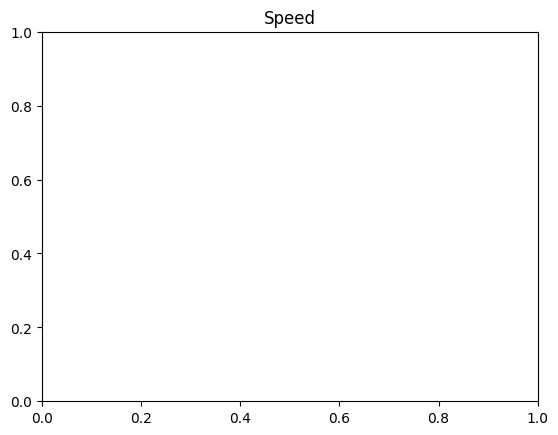

In [7]:
plt.title("Speed")
plt.plot(df.speed)
plt.show()

plt.title("steerAngle")
plt.plot(df.steerAngle)
plt.show()